# Fundamentals of Data Science: Case Studies 2 and 5

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

os.makedirs('figures', exist_ok=True)
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'text.color': 'black', 'axes.edgecolor': 'black', 'axes.labelcolor': 'black',
    'xtick.color': 'black', 'ytick.color': 'black', 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'savefig.dpi': 200,
    'axes.prop_cycle': cycler(color=['black', '0.35', '0.55', '0.75']),
})
SHADES = ['black', '0.35', '0.6', '0.8']
MARKERS = ['o', 's', '^', 'D']

def corr_heatmap(df, title, path, size=(8, 6.5)):
    corr = df.corr()
    fig, ax = plt.subplots(figsize=size)
    ax.imshow(corr.abs().values, cmap='Greys', vmin=0, vmax=1.4)
    ax.set_xticks(range(len(corr)))
    ax.set_yticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=45, ha='right')
    ax.set_yticklabels(corr.columns)
    for i in range(len(corr)):
        for j in range(len(corr)):
            v = corr.values[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(v) > 0.7 else 'black')
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

# Case Study 2: Clustering Analysis

## 2.1 Loading the Data

In [2]:
airline = pd.read_excel('data/EastWestAirlines.xlsx', sheet_name='data')
print(airline.shape)
print(airline.dtypes)
print(airline.describe().T.round(2).to_string())

(3999, 12)
ID#                  int64
Balance              int64
Qual_miles           int64
cc1_miles            int64
cc2_miles            int64
cc3_miles            int64
Bonus_miles          int64
Bonus_trans          int64
Flight_miles_12mo    int64
Flight_trans_12      int64
Days_since_enroll    int64
Award?               int64
dtype: object
                    count      mean        std  min      25%      50%      75%        max
ID#                3999.0   2014.82    1160.76  1.0   1010.5   2016.0   3020.5     4021.0
Balance            3999.0  73601.33  100775.66  0.0  18527.5  43097.0  92404.0  1704838.0
Qual_miles         3999.0    144.11     773.66  0.0      0.0      0.0      0.0    11148.0
cc1_miles          3999.0      2.06       1.38  1.0      1.0      1.0      3.0        5.0
cc2_miles          3999.0      1.01       0.15  1.0      1.0      1.0      1.0        3.0
cc3_miles          3999.0      1.01       0.20  1.0      1.0      1.0      1.0        5.0
Bonus_miles        39

## 2.2 Data Preprocessing

In [3]:
features = [c for c in airline.columns if c not in ('ID#', 'Award?') and not c.startswith('cc')]
print('Missing values:', int(airline.isnull().sum().sum()))
print('Duplicate customers:', int(airline.drop(columns='ID#').duplicated().sum()))
airline = airline.drop_duplicates(subset=[c for c in airline.columns if c != 'ID#']).reset_index(drop=True)

z = (airline[features] - airline[features].mean()) / airline[features].std()
clean = airline[(z.abs() < 5).all(axis=1)].reset_index(drop=True)
print('Rows before outlier removal:', len(airline))
print('Rows after outlier removal:', len(clean))
print('Rows removed:', len(airline) - len(clean))

X = StandardScaler().fit_transform(clean[features])
print('Scaled matrix shape:', X.shape)
print(pd.DataFrame(X, columns=features).describe().loc[['mean', 'std']].round(2).to_string())

Missing values: 0
Duplicate customers: 1
Rows before outlier removal: 3998
Rows after outlier removal: 3873
Rows removed: 125
Scaled matrix shape: (3873, 7)
      Balance  Qual_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll
mean     -0.0        -0.0         -0.0          0.0                0.0             -0.0                0.0
std       1.0         1.0          1.0          1.0                1.0              1.0                1.0


## 2.3 Exploratory Data Analysis

Balance              2.46
Bonus_miles          1.95
Bonus_trans          0.88
Flight_miles_12mo    3.98
Flight_trans_12      3.71
Days_since_enroll    0.12


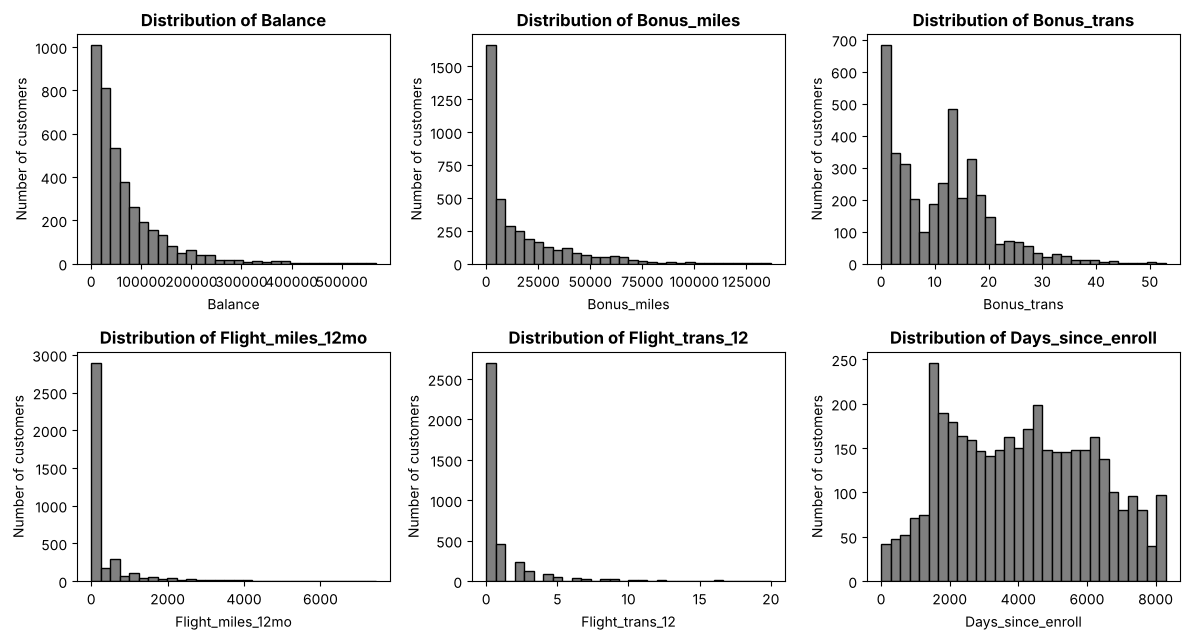

In [4]:
cols = ['Balance', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll']
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, col in zip(axes.ravel(), cols):
    ax.hist(clean[col], bins=30, color='0.5', edgecolor='black')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Number of customers')
fig.tight_layout()
fig.savefig('figures/cs2_histograms.png')
plt.show()
print(clean[cols].skew().round(2).to_string())

                   Balance  Qual_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll
Balance               1.00        0.09         0.44         0.34               0.22             0.23               0.27
Qual_miles            0.09        1.00         0.05         0.04               0.12             0.14               0.00
Bonus_miles           0.44        0.05         1.00         0.63               0.15             0.15               0.22
Bonus_trans           0.34        0.04         0.63         1.00               0.27             0.31               0.16
Flight_miles_12mo     0.22        0.12         0.15         0.27               1.00             0.87               0.06
Flight_trans_12       0.23        0.14         0.15         0.31               0.87             1.00               0.07
Days_since_enroll     0.27        0.00         0.22         0.16               0.06             0.07               1.00


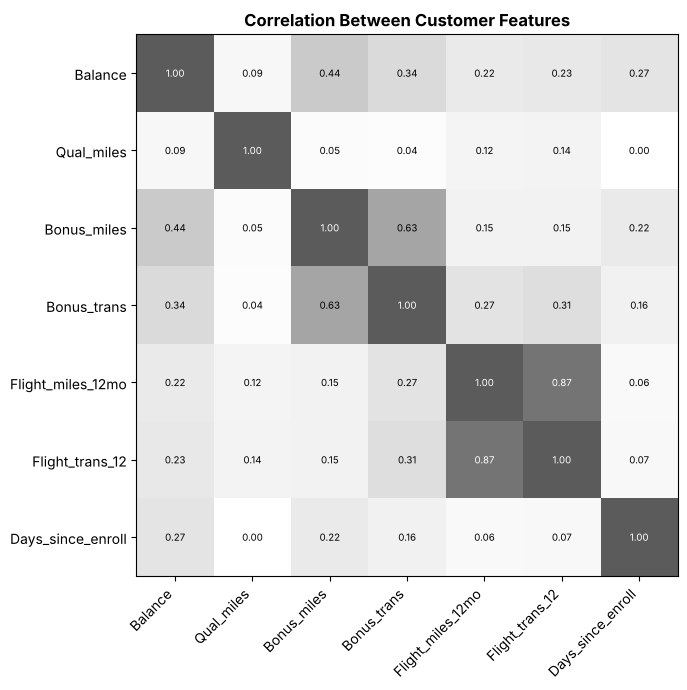

In [5]:
corr_heatmap(clean[features], 'Correlation Between Customer Features', 'figures/cs2_heatmap.png', size=(8.5, 7))
print(clean[features].corr().round(2).to_string())

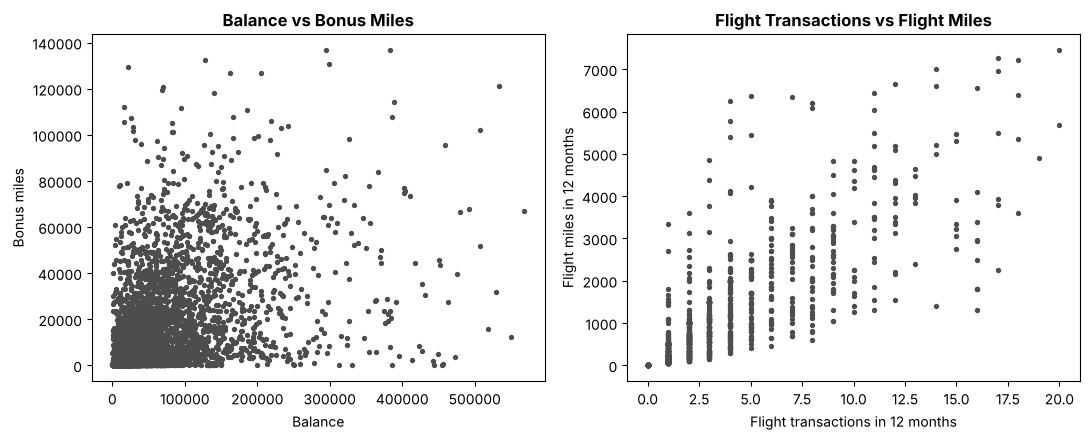

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(clean['Balance'], clean['Bonus_miles'], s=8, color='0.3')
axes[0].set_title('Balance vs Bonus Miles')
axes[0].set_xlabel('Balance')
axes[0].set_ylabel('Bonus miles')
axes[1].scatter(clean['Flight_trans_12'], clean['Flight_miles_12mo'], s=8, color='0.3')
axes[1].set_title('Flight Transactions vs Flight Miles')
axes[1].set_xlabel('Flight transactions in 12 months')
axes[1].set_ylabel('Flight miles in 12 months')
fig.tight_layout()
fig.savefig('figures/cs2_scatter_eda.png')
plt.show()

## 2.4 K-Means Clustering

 K  Inertia  Silhouette
 2  20974.0       0.398
 3  16763.0       0.306
 4  13956.0       0.319
 5  12153.0       0.245
 6  10991.0       0.245
 7  10105.0       0.253
 8   9319.0       0.258
 9   8690.0       0.253
10   8338.0       0.253


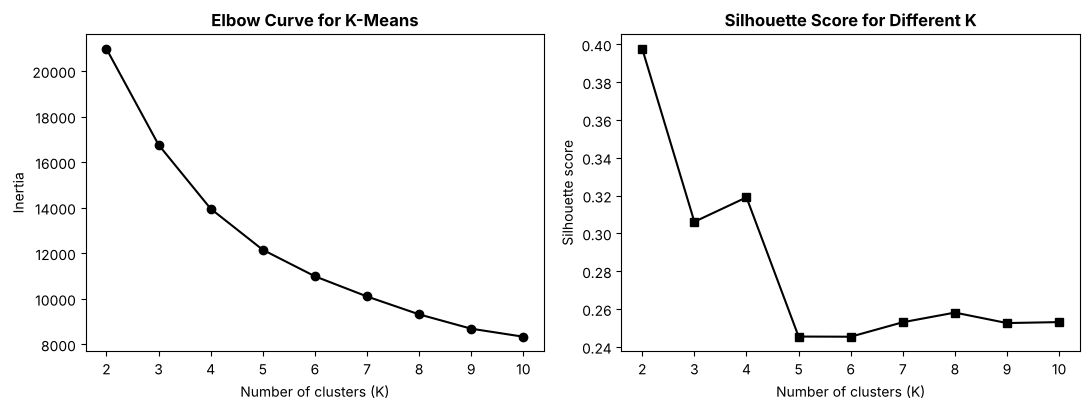

In [7]:
ks = list(range(2, 11))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
print(pd.DataFrame({'K': ks, 'Inertia': np.round(inertia, 0), 'Silhouette': np.round(sil, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(ks, inertia, marker='o', color='black')
axes[0].set_title('Elbow Curve for K-Means')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia')
axes[1].plot(ks, sil, marker='s', color='black')
axes[1].set_title('Silhouette Score for Different K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette score')
fig.tight_layout()
fig.savefig('figures/cs2_kmeans_elbow.png')
plt.show()

In [8]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
clean['KMeans'] = kmeans.labels_
print(clean['KMeans'].value_counts().sort_index().to_string())

KMeans
0    1157
1      87
2    2386
3     243


## 2.5 Hierarchical Clustering

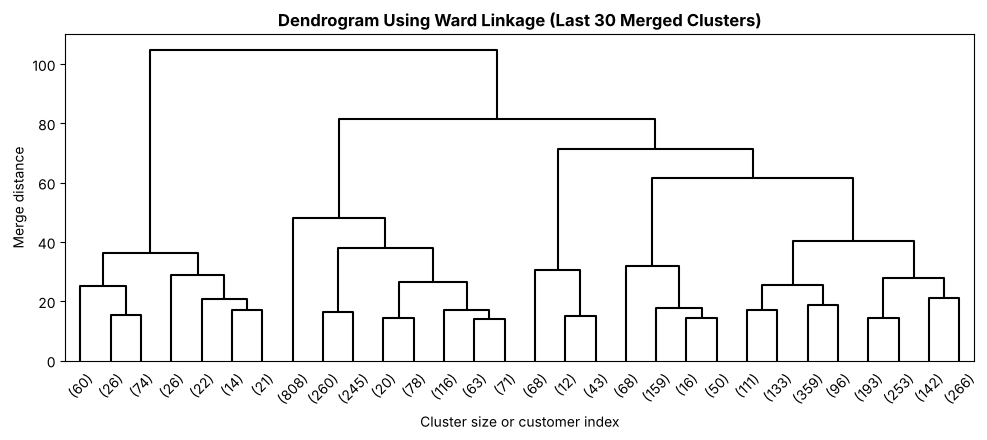

In [9]:
Z = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(10, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=0, above_threshold_color='black', ax=ax)
ax.set_title('Dendrogram Using Ward Linkage (Last 30 Merged Clusters)')
ax.set_xlabel('Cluster size or customer index')
ax.set_ylabel('Merge distance')
fig.tight_layout()
fig.savefig('figures/cs2_dendrogram.png')
plt.show()

In [10]:
rows = []
for method in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=4, linkage=method).fit_predict(X)
    rows.append({'Linkage': method,
                 'Silhouette': round(silhouette_score(X, labels), 3),
                 'Davies-Bouldin': round(davies_bouldin_score(X, labels), 3),
                 'Cluster sizes': sorted(np.bincount(labels).tolist(), reverse=True)})
print(pd.DataFrame(rows).to_string(index=False))

hier = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(X)
clean['Hierarchical'] = hier.labels_
print(clean['Hierarchical'].value_counts().sort_index().to_string())

 Linkage  Silhouette  Davies-Bouldin          Cluster sizes
    ward       0.211           1.339 [1846, 1661, 243, 123]
complete       0.593           1.091     [3729, 67, 56, 21]
 average       0.580           0.983     [3745, 116, 10, 2]
  single       0.598           0.237        [3870, 1, 1, 1]
Hierarchical
0    1846
1     243
2    1661
3     123


## 2.6 DBSCAN Clustering

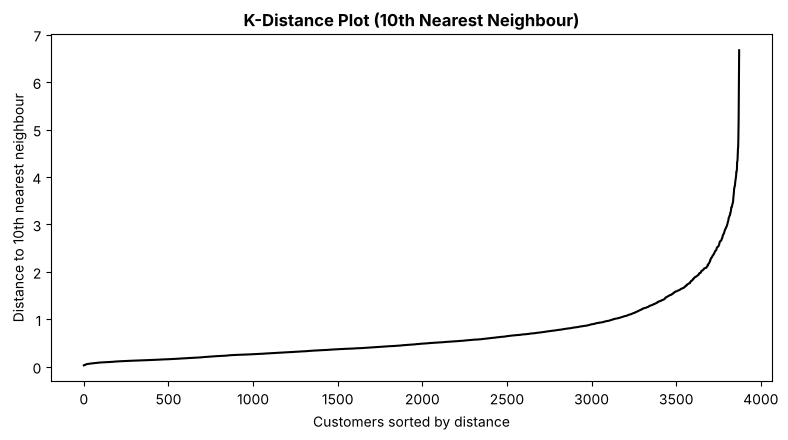

In [11]:
nn = NearestNeighbors(n_neighbors=10).fit(X)
distances, _ = nn.kneighbors(X)
kdist = np.sort(distances[:, -1])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(kdist, color='black')
ax.set_title('K-Distance Plot (10th Nearest Neighbour)')
ax.set_xlabel('Customers sorted by distance')
ax.set_ylabel('Distance to 10th nearest neighbour')
fig.tight_layout()
fig.savefig('figures/cs2_kdistance.png')
plt.show()

In [12]:
rows = []
for eps in [0.5, 1.0, 1.5, 2.0, 2.5]:
    for ms in [5, 10, 20]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        score = silhouette_score(X[mask], labels[mask]) if n_clusters > 1 else np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'clusters': n_clusters,
                     'noise': int((~mask).sum()), 'silhouette': round(score, 3) if n_clusters > 1 else np.nan})
grid = pd.DataFrame(rows)
print(grid.to_string(index=False))

valid = grid[(grid['clusters'] >= 2) & (grid['noise'] <= 0.1 * len(X))]
best = valid.sort_values('silhouette', ascending=False).iloc[0]
print(best.to_string())

dbscan = DBSCAN(eps=float(best['eps']), min_samples=int(best['min_samples'])).fit(X)
clean['DBSCAN'] = dbscan.labels_
print(clean['DBSCAN'].value_counts().sort_index().to_string())

 eps  min_samples  clusters  noise  silhouette
 0.5            5         8   1235      -0.141
 0.5           10         2   1491       0.207
 0.5           20         1   1734         NaN
 1.0            5         5    453       0.212
 1.0           10         1    565         NaN
 1.0           20         1    640         NaN
 1.5            5         2    212       0.438
 1.5           10         2    269       0.617
 1.5           20         1    351         NaN
 2.0            5         1    103         NaN
 2.0           10         1    126         NaN
 2.0           20         2    158       0.601
 2.5            5         2     48       0.516
 2.5           10         1     69         NaN
 2.5           20         1     82         NaN
eps              1.500
min_samples     10.000
clusters         2.000
noise          269.000
silhouette       0.617
DBSCAN
-1     269
 0    3579
 1      25


## 2.7 Cluster Visualization

[0.365 0.208] 0.573


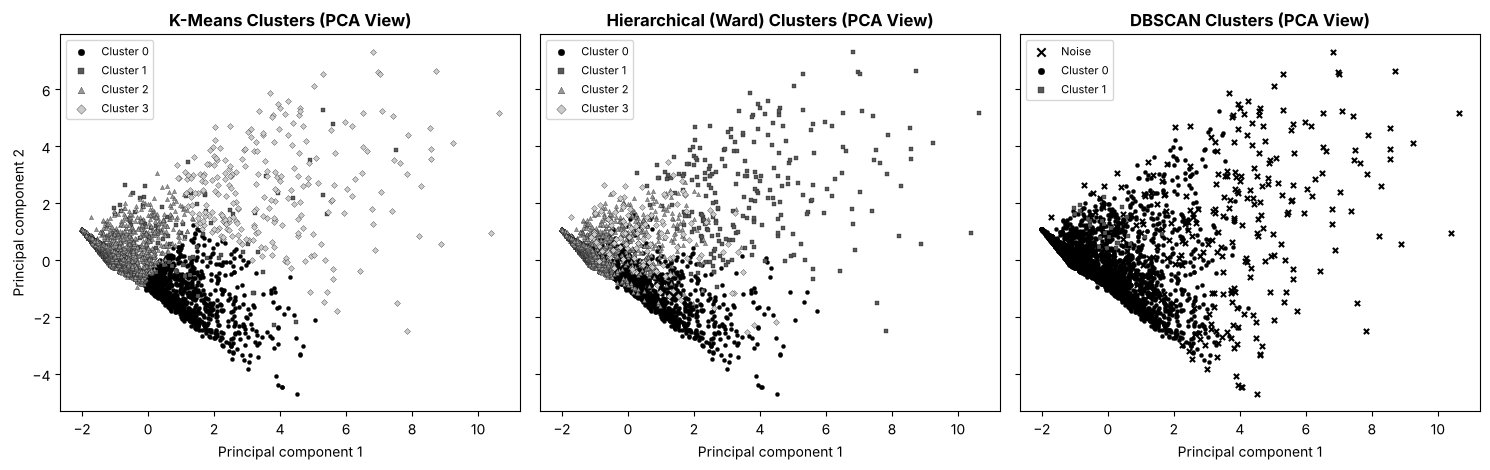

In [13]:
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
print(pca.explained_variance_ratio_.round(3), pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
for ax, col, name in zip(axes, ['KMeans', 'Hierarchical', 'DBSCAN'], ['K-Means', 'Hierarchical (Ward)', 'DBSCAN']):
    labels = clean[col].values
    for i, lab in enumerate(sorted(set(labels))):
        m = labels == lab
        if lab == -1:
            ax.scatter(P[m, 0], P[m, 1], s=14, marker='x', color='black', label='Noise')
        else:
            ax.scatter(P[m, 0], P[m, 1], s=9, marker=MARKERS[lab % 4], color=SHADES[lab % 4],
                       edgecolor='black', linewidth=0.2, label=f'Cluster {lab}')
    ax.set_title(f'{name} Clusters (PCA View)')
    ax.set_xlabel('Principal component 1')
    ax.legend(markerscale=1.6, fontsize=8)
axes[0].set_ylabel('Principal component 2')
fig.tight_layout()
fig.savefig('figures/cs2_cluster_scatter.png')
plt.show()

## 2.8 Cluster Profiles

In [14]:
profile_cols = ['Balance', 'Qual_miles', 'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12', 'Days_since_enroll', 'Award?']
for col in ['KMeans', 'Hierarchical', 'DBSCAN']:
    prof = clean.groupby(col)[profile_cols].mean().round(2)
    prof.insert(0, 'Customers', clean.groupby(col).size())
    print(col)
    print(prof.to_string())
    print()

KMeans
        Customers    Balance  Qual_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
KMeans                                                                                                                           
0            1157  117369.12       13.31     36598.03        18.56             210.24             0.67            5125.55    0.52
1              87   97916.39     2383.74     19638.95        12.01             614.51             1.97            4183.72    0.62
2            2386   35667.12       10.19      5063.13         6.63             115.98             0.40            3568.45    0.24
3             243  118819.58      125.74     25373.77        20.40            3080.52             8.72            4420.52    0.65

Hierarchical
              Customers    Balance  Qual_miles  Bonus_miles  Bonus_trans  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
Hierarchical                                                   

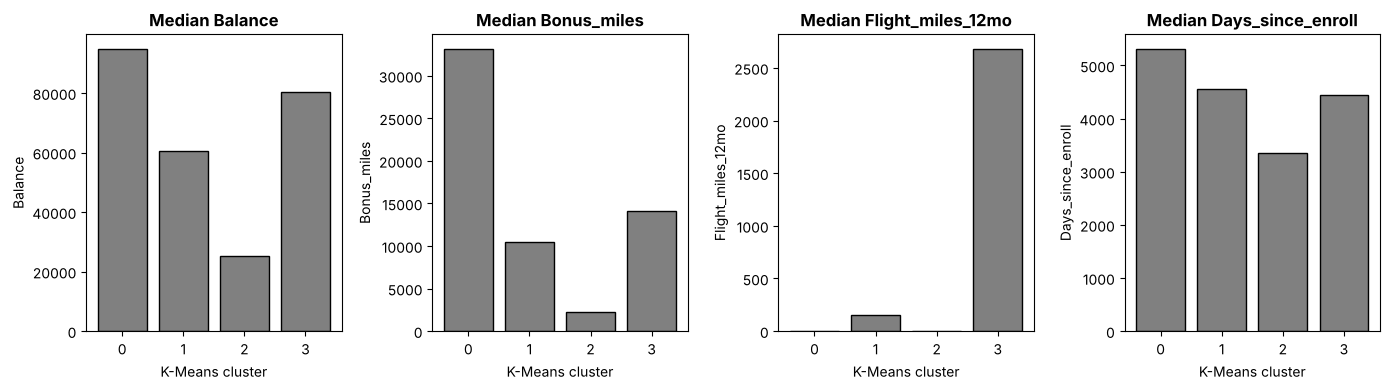

In [15]:
medians = clean.groupby('KMeans')[['Balance', 'Bonus_miles', 'Flight_miles_12mo', 'Days_since_enroll']].median()
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, col in zip(axes, medians.columns):
    ax.bar(medians.index.astype(str), medians[col], color='0.5', edgecolor='black')
    ax.set_title(f'Median {col}')
    ax.set_xlabel('K-Means cluster')
    ax.set_ylabel(col)
fig.tight_layout()
fig.savefig('figures/cs2_cluster_profiles.png')
plt.show()

## 2.9 Evaluation Summary

In [16]:
summary = []
for col, name in [('KMeans', 'K-Means'), ('Hierarchical', 'Hierarchical (Ward)'), ('DBSCAN', 'DBSCAN')]:
    labels = clean[col].values
    m = labels != -1
    summary.append({'Method': name, 'Clusters': len(set(labels[m])), 'Noise points': int((~m).sum()),
                    'Silhouette': round(silhouette_score(X[m], labels[m]), 3),
                    'Davies-Bouldin': round(davies_bouldin_score(X[m], labels[m]), 3)})
print(pd.DataFrame(summary).to_string(index=False))

             Method  Clusters  Noise points  Silhouette  Davies-Bouldin
            K-Means         4             0       0.319           1.178
Hierarchical (Ward)         4             0       0.211           1.339
             DBSCAN         2           269       0.617           0.515


# Case Study 5: Wine Quality Assessment

## 3.1 Loading the Data

In [17]:
red = pd.read_csv('data/winequality-red.csv', sep=';')
white = pd.read_csv('data/winequality-white.csv', sep=';')
wine = pd.concat([red, white], ignore_index=True)
wine_type = np.array(['red'] * len(red) + ['white'] * len(white))
print(red.shape, white.shape, wine.shape)
print('Missing values:', int(wine.isnull().sum().sum()))
print(wine.describe().T.round(3).to_string())

(1599, 12) (4898, 12) (6497, 12)
Missing values: 0
                       count     mean     std    min     25%      50%      75%      max
fixed acidity         6497.0    7.215   1.296  3.800   6.400    7.000    7.700   15.900
volatile acidity      6497.0    0.340   0.165  0.080   0.230    0.290    0.400    1.580
citric acid           6497.0    0.319   0.145  0.000   0.250    0.310    0.390    1.660
residual sugar        6497.0    5.443   4.758  0.600   1.800    3.000    8.100   65.800
chlorides             6497.0    0.056   0.035  0.009   0.038    0.047    0.065    0.611
free sulfur dioxide   6497.0   30.525  17.749  1.000  17.000   29.000   41.000  289.000
total sulfur dioxide  6497.0  115.745  56.522  6.000  77.000  118.000  156.000  440.000
density               6497.0    0.995   0.003  0.987   0.992    0.995    0.997    1.039
pH                    6497.0    3.219   0.161  2.720   3.110    3.210    3.320    4.010
sulphates             6497.0    0.531   0.149  0.220   0.430    0.510

## 3.2 Task 1: Statistical Analysis

In [18]:
attrs = ['alcohol', 'volatile acidity', 'residual sugar']
rows = []
for a in attrs:
    rows.append({'Attribute': a, 'Mean': wine[a].mean(), 'Median': wine[a].median(),
                 'Mode': wine[a].mode().iloc[0], 'Std Dev': wine[a].std(),
                 'Skewness': wine[a].skew(), 'CV (%)': wine[a].std() / wine[a].mean() * 100})
desc = pd.DataFrame(rows).set_index('Attribute').round(3)
print(desc.to_string())
print('Highest relative variability:', desc['CV (%)'].idxmax())

r, p = stats.pearsonr(wine['alcohol'], wine['quality'])
print('Pearson r (alcohol, quality):', round(r, 4))
print('p-value:', p)

                    Mean  Median  Mode  Std Dev  Skewness  CV (%)
Attribute                                                        
alcohol           10.492   10.30  9.50    1.193     0.566  11.368
volatile acidity   0.340    0.29  0.28    0.165     1.495  48.470
residual sugar     5.443    3.00  2.00    4.758     1.435  87.408
Highest relative variability: residual sugar
Pearson r (alcohol, quality): 0.4443
p-value: 1.49754444766e-312


## 3.3 Task 2: Exploratory Data Analysis

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
quality
3     0.46
4     3.32
5    32.91
6    43.65
7    16.61
8     2.97
9     0.08


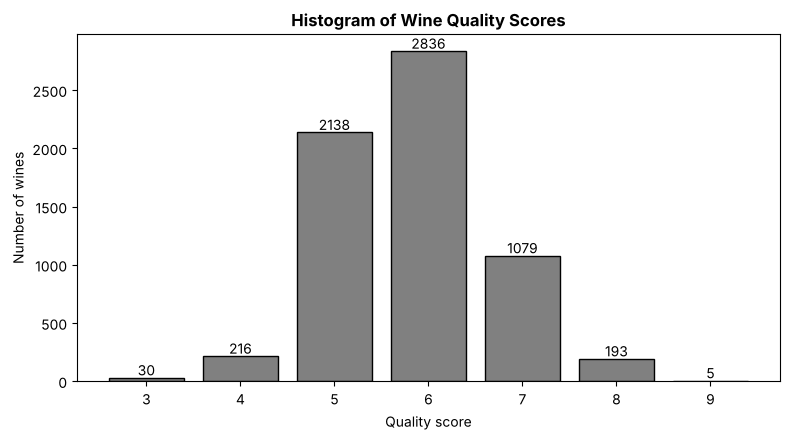

In [19]:
counts = wine['quality'].value_counts().sort_index()
print(counts.to_string())
print((counts / len(wine) * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(counts.index.astype(str), counts.values, color='0.5', edgecolor='black')
for x, v in zip(range(len(counts)), counts.values):
    ax.text(x, v + 20, str(v), ha='center')
ax.set_title('Histogram of Wine Quality Scores')
ax.set_xlabel('Quality score')
ax.set_ylabel('Number of wines')
fig.tight_layout()
fig.savefig('figures/cs5_quality_histogram.png')
plt.show()

 Quality  Wines  Median alcohol  Outliers
       3     30           10.15         0
       4    216           10.00         1
       5   2138            9.60        55
       6   2836           10.50         0
       7   1079           11.40         0
       8    193           12.00         1
       9      5           12.50         1


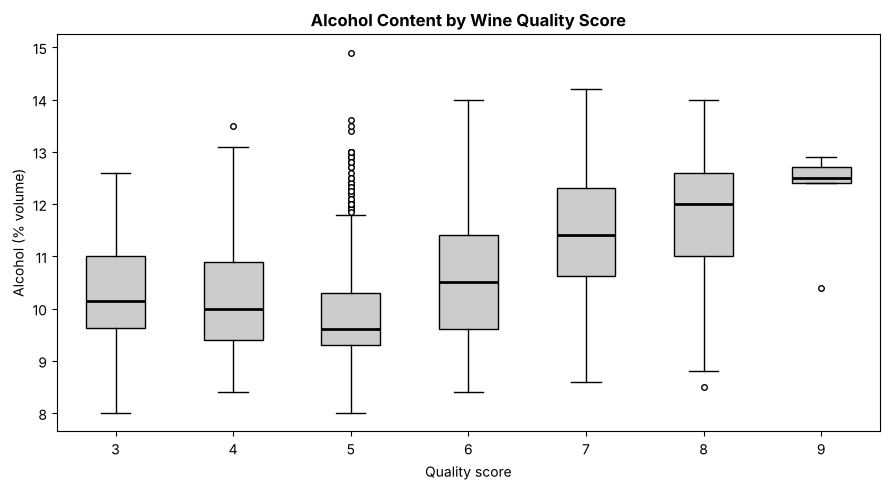

In [20]:
levels = sorted(wine['quality'].unique())
data = [wine.loc[wine['quality'] == q, 'alcohol'] for q in levels]
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(data, tick_labels=[str(q) for q in levels], patch_artist=True,
           boxprops=dict(facecolor='0.8', edgecolor='black'), medianprops=dict(color='black', linewidth=2),
           whiskerprops=dict(color='black'), capprops=dict(color='black'),
           flierprops=dict(marker='o', markerfacecolor='white', markeredgecolor='black', markersize=4))
ax.set_title('Alcohol Content by Wine Quality Score')
ax.set_xlabel('Quality score')
ax.set_ylabel('Alcohol (% volume)')
fig.tight_layout()
fig.savefig('figures/cs5_alcohol_boxplot.png')
plt.show()

rows = []
for q, d in zip(levels, data):
    q1, q3 = d.quantile(0.25), d.quantile(0.75)
    iqr = q3 - q1
    out = int(((d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)).sum())
    rows.append({'Quality': q, 'Wines': len(d), 'Median alcohol': round(d.median(), 2), 'Outliers': out})
print(pd.DataFrame(rows).to_string(index=False))

alcohol                 0.444
density                -0.306
volatile acidity       -0.266
chlorides              -0.201
citric acid             0.086
fixed acidity          -0.077
free sulfur dioxide     0.055
total sulfur dioxide   -0.041
sulphates               0.038
residual sugar         -0.037
pH                      0.020
Top two: ['alcohol', 'density']


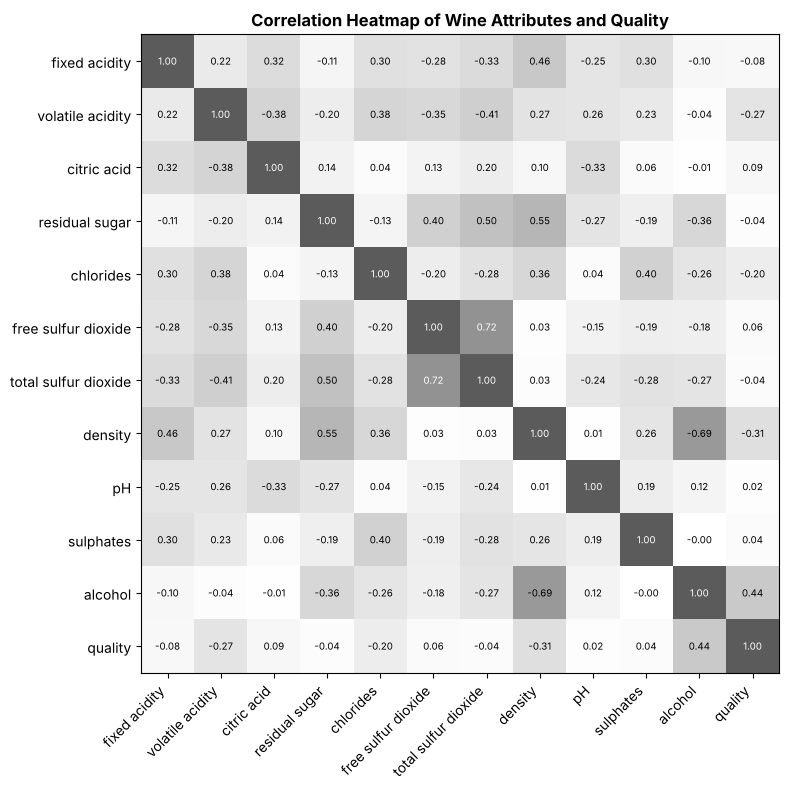

In [21]:
corr_heatmap(wine, 'Correlation Heatmap of Wine Attributes and Quality', 'figures/cs5_heatmap.png', size=(9.5, 8))
qcorr = wine.corr()['quality'].drop('quality')
print(qcorr.round(3).sort_values(key=abs, ascending=False).to_string())
print('Top two:', list(qcorr.abs().sort_values(ascending=False).index[:2]))

## 3.4 Task 3: Predictive Modelling

In [22]:
inputs = [c for c in wine.columns if c != 'quality']
X_wine = wine[inputs]
y_wine = wine['quality']
X_train, X_test, y_train, y_test, type_train, type_test = train_test_split(
    X_wine, y_wine, wine_type, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred)
print('MAE :', round(mae, 4))
print('MSE :', round(mse, 4))
print('RMSE:', round(rmse, 4))
print('R2  :', round(r2, 4))
print('Baseline RMSE (always predict the training mean):',
      round(np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))), 4))

rounded = np.clip(np.round(pred), 3, 9)
print('Exact match after rounding (%):', round((rounded == y_test).mean() * 100, 1))
print('Within one point (%):', round((np.abs(rounded - y_test) <= 1).mean() * 100, 1))

(5197, 11) (1300, 11)
MAE : 0.5659
MSE : 0.5467
RMSE: 0.7394
R2  : 0.2598
Baseline RMSE (always predict the training mean): 0.8596
Exact match after rounding (%): 53.9
Within one point (%): 94.8


In [23]:
scaler = StandardScaler().fit(X_train)
std_model = LinearRegression().fit(scaler.transform(X_train), y_train)
std_coef = pd.Series(std_model.coef_, index=inputs)
print(std_coef.sort_values(key=abs, ascending=False).round(3).to_string())

vif = {}
for col in inputs:
    others = [c for c in inputs if c != col]
    r2_col = LinearRegression().fit(X_train[others], X_train[col]).score(X_train[others], X_train[col])
    vif[col] = 1 / (1 - r2_col)
print(pd.Series(vif).sort_values(ascending=False).round(2).to_string())

alcohol                 0.322
residual sugar          0.220
volatile acidity       -0.219
density                -0.177
total sulfur dioxide   -0.150
free sulfur dioxide     0.123
sulphates               0.120
fixed acidity           0.102
pH                      0.077
citric acid            -0.021
chlorides              -0.012
density                 15.51
residual sugar           7.20
fixed acidity            4.74
alcohol                  4.62
total sulfur dioxide     2.96
pH                       2.47
free sulfur dioxide      2.16
volatile acidity         1.94
chlorides                1.65
citric acid              1.61
sulphates                1.54


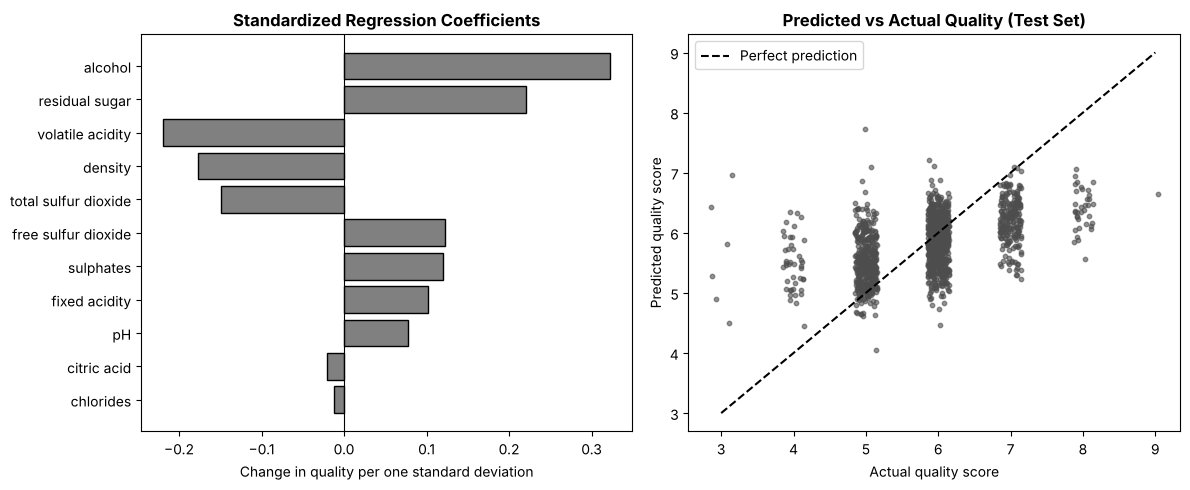

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
order = std_coef.sort_values(key=abs)
axes[0].barh(order.index, order.values, color='0.5', edgecolor='black')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Standardized Regression Coefficients')
axes[0].set_xlabel('Change in quality per one standard deviation')
rng = np.random.default_rng(42)
axes[1].scatter(y_test + rng.uniform(-0.15, 0.15, len(y_test)), pred, s=10, color='0.3', alpha=0.6)
axes[1].plot([3, 9], [3, 9], color='black', linestyle='--', label='Perfect prediction')
axes[1].set_title('Predicted vs Actual Quality (Test Set)')
axes[1].set_xlabel('Actual quality score')
axes[1].set_ylabel('Predicted quality score')
axes[1].legend()
fig.tight_layout()
fig.savefig('figures/cs5_model_plots.png')
plt.show()

In [25]:
for t in ['red', 'white']:
    idx = wine_type == t
    Xt, Xs, yt, ys = train_test_split(X_wine[idx], y_wine[idx], test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xt, yt)
    p = m.predict(Xs)
    print(t, 'MAE', round(mean_absolute_error(ys, p), 4), 'RMSE', round(np.sqrt(mean_squared_error(ys, p)), 4), 'R2', round(r2_score(ys, p), 4))

red MAE 0.5035 RMSE 0.6245 R2 0.4032
white MAE 0.5863 RMSE 0.7543 R2 0.2653


## 3.5 Task 4: Business Decision-Making

In [26]:
summary = pd.DataFrame({'Correlation with quality': qcorr.round(3), 'Standardized coefficient': std_coef.round(3)})
print(summary.sort_values('Standardized coefficient', key=abs, ascending=False).to_string())
print('Test R2:', round(r2, 4), '| Test RMSE:', round(rmse, 4), '| Test MAE:', round(mae, 4))

                      Correlation with quality  Standardized coefficient
alcohol                                  0.444                     0.322
residual sugar                          -0.037                     0.220
volatile acidity                        -0.266                    -0.219
density                                 -0.306                    -0.177
total sulfur dioxide                    -0.041                    -0.150
free sulfur dioxide                      0.055                     0.123
sulphates                                0.038                     0.120
fixed acidity                           -0.077                     0.102
pH                                       0.020                     0.077
citric acid                              0.086                    -0.021
chlorides                               -0.201                    -0.012
Test R2: 0.2598 | Test RMSE: 0.7394 | Test MAE: 0.5659
